# 第四周作业：基于 tushare 的上市公司数据分析

**公司：贵州茅台（600519.SH）**
**学号：42531056　姓名：聂语彤　日期：2026-10-11**

> **选题说明**：原计划分析跨境电商公司 SHEIN，但该公司尚未在任何交易所上市，tushare 中无法获取其行情与财务数据；故改选同为"消费零售"赛道、且在 tushare 数据完备的上市公司——**贵州茅台**，作为本次分析标的。

## 第一部分：公司名称与基本简介

**贵州茅台**（股票代码 **600519.SH**）于 **2001-08-27** 在上交所主板上市，所属行业为白酒，注册地为贵州省遵义市仁怀市。

- 主要产品为**贵州茅台酒**（53%vol 飞天茅台等）及系列酒，是**世界范围内知名度极高的高端烈性酒品牌**；
- 商业模式"护城河"极深：品牌 + 地理标志（茅台镇产区）+ 基酒产能稀缺，毛利率常年维持在 **91%~92%** 的超高水平，ROE 长期在 **30%~40%** 之间；
- 被市场称为"A股之王"，长期是沪深两市市值最高的公司之一，也是价值投资与长期复利的代表性标的。

本报告将结合 tushare 提供的**行情数据、估值指标、财务指标与宏观（CPI）**数据，回答一个关于其长期回报来源的问题。

## 第二部分：研究问题题目及其内涵介绍

**研究问题：贵州茅台 2005 年以来相对沪深 300 指数的超额收益有多大？其股价长期回报是否与业绩高成长相匹配？2021 年以来业绩增速放缓是否引发了股价的"杀估值"调整？**

### 内涵介绍
1. **超额收益**：茅台作为高 ROE、高毛利样本，"股王"地位真实存在吗？用后复权价格与沪深 300 净值对比，量化其相对市场的超额回报；
2. **风险特征**：高收益的代价是什么？通过年度涨幅分布、最大回撤、年化波动率刻画持有体验；
3. **股价与业绩的关系**：茅台的长期涨幅是"炒作"还是"业绩增长"的映射？通过对比历年营收/净利同比增速与股价年度涨幅，检验二者相关性；
4. **估值视角**：市场给予茅台的估值（市盈率 PE-TTM）发生了怎样的变化？2021 年的估值泡沫与随后的"杀估值"如何量化？
5. **增速拐点与宏观**：2021 年以来外部环境与高端酒需求降温，公司净利增速持续回落并于 2025 年首次转负，本报告将观察这一基本面变化是否同步体现在股价上；并引入 CPI 作为消费景气的代理变量，考察股价年度表现与通胀之间的相关性。

> 数据口径：股价收益一律用**后复权**（复权因子×收盘价）计算，避免分红送转造成失真；基准指数使用沪深 300（000300.SH）；估值使用 `daily_basic` 的 PE-TTM；宏观使用全国 CPI 同比（cn_cpi）。

## 第三部分：数据采集

> 为方便批改，**token 直接写入代码**（如下）。tushare 对普通 token 有接口频次限制，为保证结果可复现，代码采用**"先查本地缓存、缓存缺失再在线抓取并落盘"**策略。

采集内容（全部来自 tushare pro）：
| 数据集 | 接口 | 用途 |
|---|---|---|
| 贵州茅台日行情 | `pro.daily` | 价格序列 |
| 复权因子 | `pro.adj_factor` | 计算后复权真实收益 |
| 沪深 300 指数 | `pro.index_daily` | 市场基准 |
| 每日估值指标 | `pro.daily_basic` | 市盈率 PE-TTM、市净率、总市值 |
| 财务指标 | `pro.fina_indicator` | ROE、毛利率、营收/净利同比 |
| 全国 CPI | `pro.cn_cpi` | 消费景气宏观测度 |

In [1]:
# ------ 数据采集 ------
import os, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import tushare as ts

warnings.filterwarnings("ignore")

TOKEN = "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521"
PROJ = "600519.SH"
DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

plt.rcParams["font.sans-serif"] = ["PingFang SC", "Heiti SC", "STHeiti", "Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False

ts.set_token(TOKEN)
pro = ts.pro_api()

def fetch(save_name, fn, cols):
    path = os.path.join(DATA_DIR, save_name)
    if os.path.exists(path):
        df = pd.read_csv(path, dtype={"trade_date": str, "end_date": str, "month": str})
        source = "本地缓存"
    else:
        df = fn()
        if df is None or df.empty:
            raise RuntimeError(f"接口无数据：{save_name}")
        df = df[cols]
        df.to_csv(path, index=False)
        source = "tushare 在线抓取"
    print(f"[{source:>10}] {save_name:18s} {len(df)} 条")
    return df

daily = fetch("mt_daily.csv",
              lambda: pro.daily(ts_code=PROJ, start_date="20010101", end_date="20261010"),
              ["trade_date", "open", "high", "low", "close", "pre_close", "pct_chg", "vol", "amount"])
adj  = fetch("mt_adj.csv",
             lambda: pro.adj_factor(ts_code=PROJ, start_date="20010101", end_date="20261010"),
             ["trade_date", "adj_factor"])
hs300 = fetch("hs300_daily.csv",
              lambda: pro.index_daily(ts_code="000300.SH", start_date="20050101", end_date="20261010"),
              ["trade_date", "close"])
pe_df = fetch("mt_daily_basic.csv",
              lambda: pro.daily_basic(ts_code=PROJ, start_date="20050101", end_date="20261010",
                                      fields="ts_code,trade_date,close,pe,pb,total_mv"),
              ["trade_date", "pe", "pb", "total_mv"])
fina = fetch("mt_fina.csv",
             lambda: pro.fina_indicator(ts_code=PROJ, start_date="20011231", end_date="20261231"),
             ["end_date", "roe", "grossprofit_margin", "netprofit_margin", "eps",
              "debt_to_assets", "or_yoy", "netprofit_yoy"])
cpi  = fetch("cn_cpi.csv",
             lambda: pro.cn_cpi(start_m="20010101", end_m="20261001"),
             ["month", "nt_yoy"])

print("\n贵州茅台日行情（最新 5 行）:")
print(daily.head())

print("\n财务指标（格式示例）:")
print(fina.head(3))

[      本地缓存] mt_daily.csv       6000 条
[      本地缓存] mt_adj.csv         6000 条
[      本地缓存] hs300_daily.csv    5284 条
[      本地缓存] mt_daily_basic.csv 5216 条
[      本地缓存] mt_fina.csv        25 条
[      本地缓存] cn_cpi.csv         307 条

贵州茅台日行情（最新 5 行）:
  trade_date     open     high      low    close  pre_close  pct_chg  \
0   20261009  1255.42  1282.00  1255.42  1263.00    1255.79   0.5741   
1   20261008  1252.90  1258.00  1242.00  1255.79    1258.62  -0.2248   
2   20260930  1239.53  1268.00  1236.05  1258.62    1235.58   1.8647   
3   20260929  1244.60  1245.87  1230.88  1235.58    1243.88  -0.6673   
4   20260928  1236.00  1244.01  1228.10  1243.88    1237.00   0.5562   

        vol       amount  
0  35110.51  4453223.189  
1  25167.57  3145413.157  
2  38330.98  4797246.636  
3  26366.30  3260057.865  
4  28218.30  3488720.613  

财务指标（格式示例）:
   end_date      roe  grossprofit_margin  netprofit_margin    eps  \
0  20251231  34.4620             91.1796           50.5279  65.66   
1  20

## 第四部分：数据分析过程

### 4.1 数据处理：后复权与基准对齐

- 后复权价格：`复权价 = 收盘价 × 复权因子`；
- 以沪深 300 起始日（2005-01-04）为共同参照点，分别计算茅台与沪深 300 的累计净值；
- 估值数据（PE-TTM）与财务数据（年报口径）分别按交易日、年度整理。

In [2]:
# ------ 数据处理 ------
daily["trade_date"] = pd.to_datetime(daily["trade_date"], format="%Y%m%d")
adj["trade_date"]   = pd.to_datetime(adj["trade_date"], format="%Y%m%d")
hs300["trade_date"] = pd.to_datetime(hs300["trade_date"], format="%Y%m%d")
pe_df["trade_date"] = pd.to_datetime(pe_df["trade_date"], format="%Y%m%d")

stock = daily.merge(adj, on="trade_date").sort_values("trade_date").set_index("trade_date")
stock["hfq"] = stock["close"] * stock["adj_factor"]

hs300 = hs300.sort_values("trade_date").set_index("trade_date")
pe_df = pe_df.sort_values("trade_date").set_index("trade_date")

# 对齐起点：以沪深300最早日期为准（2005-01-04）
t0 = hs300.index[0]
maotai = stock["hfq"].loc[t0:]
bench  = hs300["close"].loc[t0:]

nav_mt   = maotai / maotai.iloc[0]          # 茅台累计净值
nav_hs300 = bench / bench.iloc[0]           # 沪深300累计净值
excess_net = nav_mt / nav_hs300             # 超额净值

print(f"数据区间：{t0.strftime('%Y-%m-%d')} ~ {stock.index[-1].strftime('%Y-%m-%d')}")
print(f"茅台累计涨幅：{nav_mt.iloc[-1]-1:+.1%}（{nav_mt.iloc[-1]:.1f} 倍）")
print(f"沪深300累计涨幅：{nav_hs300.iloc[-1]-1:+.1%}（{nav_hs300.iloc[-1]:.1f} 倍）")
print(f"相对超额（净值比）：{excess_net.iloc[-1]:.1f} 倍")
print(f"若自2001年上市起算，后复权累计涨幅：{stock['hfq'].iloc[-1]/stock['hfq'].iloc[0]:.1f} 倍")

# 年度后复权涨幅
annual = stock["hfq"].groupby(stock.index.year).agg(["first", "last"])
annual_ret = (annual["last"] / annual["first"] - 1).dropna() * 100
print("\n年度后复权涨幅（%）:")
print(annual_ret.round(1).to_string())

数据区间：2005-01-04 ~ 2026-10-09
茅台累计涨幅：+18325.3%（184.3 倍）
沪深300累计涨幅：+339.3%（4.4 倍）
相对超额（净值比）：41.9 倍
若自2001年上市起算，后复权累计涨幅：302.9 倍

年度后复权涨幅（%）:
trade_date
2002    -21.0
2003     14.0
2004     90.7
2005     51.6
2006    354.6
2007    169.6
2008    -50.8
2009     57.9
2010      9.2
2011     15.9
2012     14.6
2013    -35.9
2014     70.1
2015     20.6
2016     62.5
2017    111.6
2018    -15.0
2019    100.4
2020     78.9
2021      3.6
2022    -13.8
2023      2.5
2024     -6.2
2025     -4.0
2026     -9.3


### 4.2 长期收益：茅台 vs 沪深300 累计净值与超额净值

用**对数坐标**展示累计净值（否则茅台后期涨幅会压扁早期波动），并用"茅台净值 ÷ 沪深300净值"直接刻画超额收益的积累与回吐。

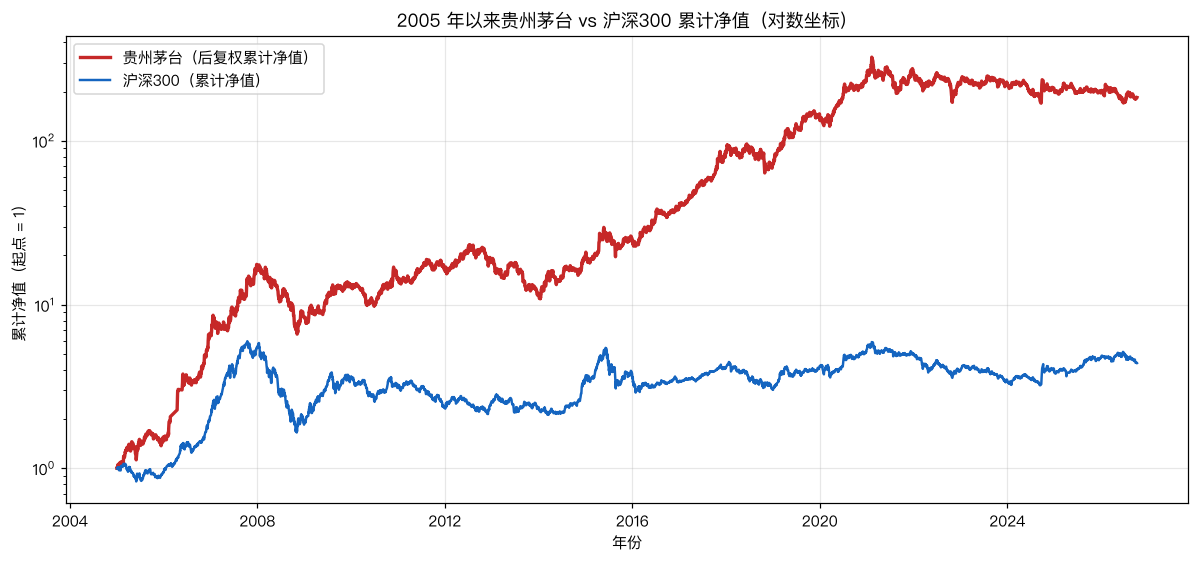

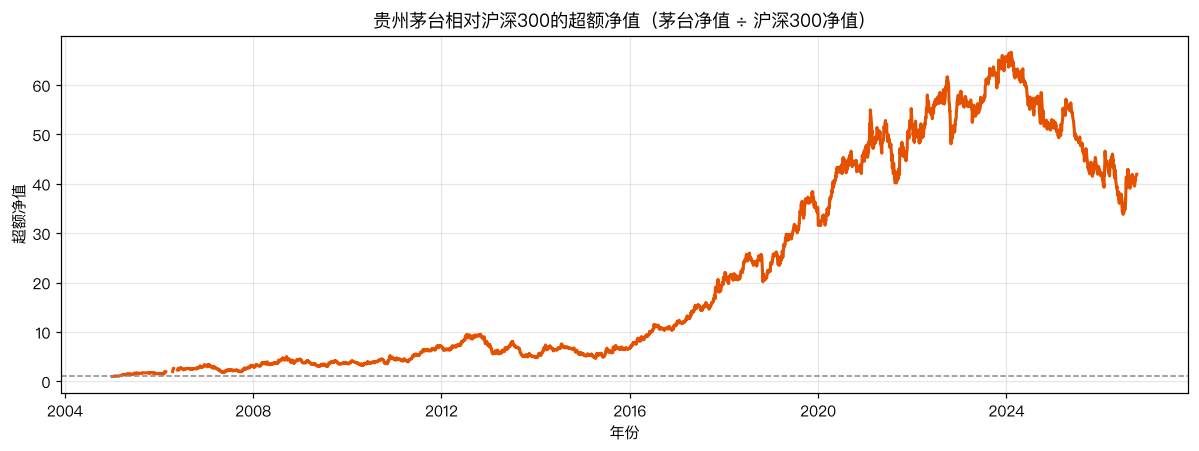

In [3]:
# ------ 图1：茅台 vs 沪深300 累计净值（对数坐标） ------
fig, ax = plt.subplots(figsize=(11, 5.2), dpi=110)
ax.plot(nav_mt.index, nav_mt, label="贵州茅台（后复权累计净值）", lw=2.2, color="#c62828")
ax.plot(nav_hs300.index, nav_hs300, label="沪深300（累计净值）", lw=1.6, color="#1565c0")
ax.set_yscale("log")
ax.set_title("2005 年以来贵州茅台 vs 沪深300 累计净值（对数坐标）")
ax.set_xlabel("年份"); ax.set_ylabel("累计净值（起点 = 1）")
ax.legend(loc="upper left"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# ------ 图2：相对沪深300的超额净值 ------
fig, ax = plt.subplots(figsize=(11, 4.2), dpi=110)
ax.plot(excess_net.index, excess_net, color="#e65100", lw=2)
ax.axhline(1.0, color="#888", ls="--", lw=1)
ax.set_title("贵州茅台相对沪深300的超额净值（茅台净值 ÷ 沪深300净值）")
ax.set_xlabel("年份"); ax.set_ylabel("超额净值")
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### 4.3 风险特征：年度涨幅分布与最大回撤

"股王"并非只涨不跌。用**年度后复权涨幅柱状图**（红涨绿跌）和**回撤曲线**（净值距历史高点的距离）刻画持有茅台的真实体验，并计算年化波动率、最大回撤等风险指标。

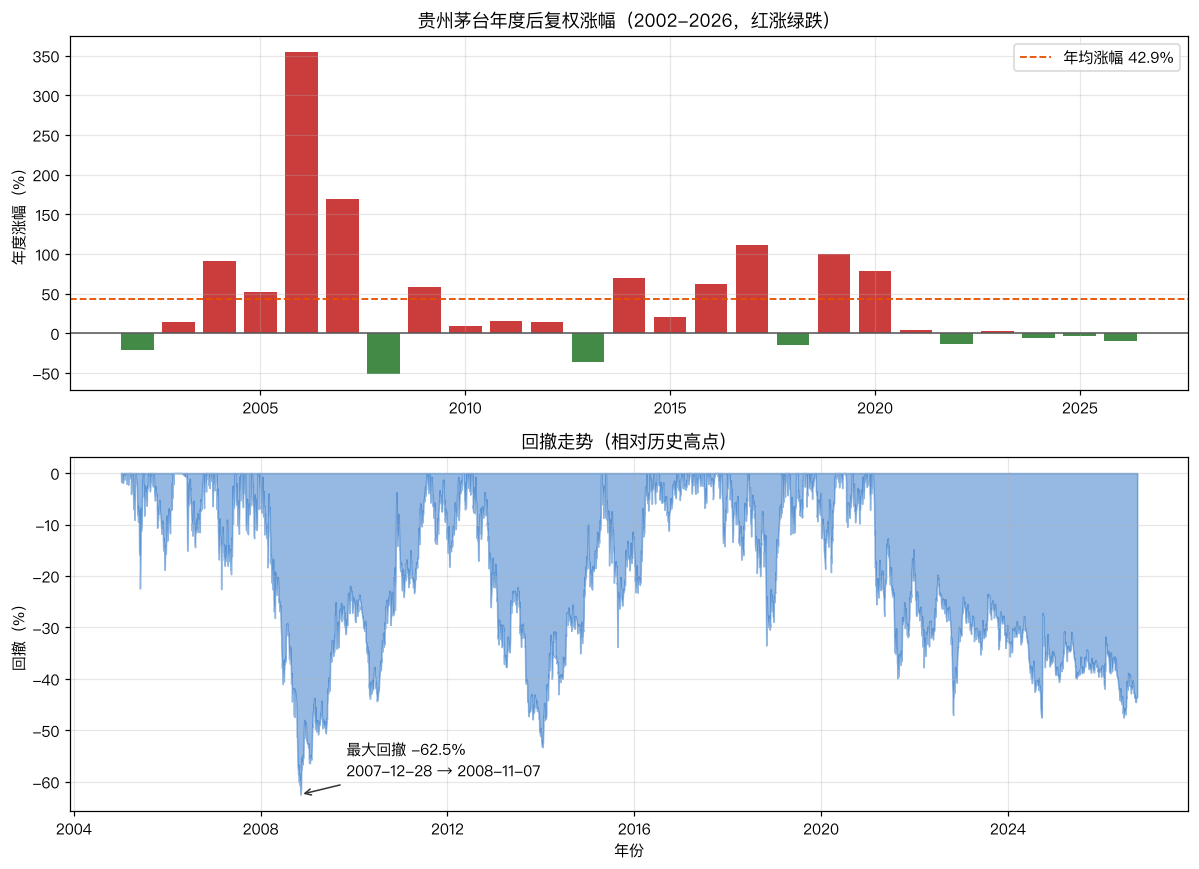

====== 风险收益指标（2005-01-04 至今，后复权口径）======
年化收益率（CAGR）：27.6%
年化波动率：        32.0%
最大回撤：          -62.5%（2007-12-28 → 2008-11-07，修复日 2011-07-21）
年度涨幅：均值 42.9%，中位数 14.6%
上涨年份占比：17/25 年
单日最大跌幅：-10.0%（2018-10-29）


In [4]:
# ------ 图6：年度涨幅分布 + 回撤曲线 ------
ret_daily = maotai.pct_change().dropna()
dd = nav_mt / nav_mt.cummax() - 1

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8), dpi=110)

# 上：年度涨幅
colors = ["#c62828" if v >= 0 else "#2e7d32" for v in annual_ret.values]
ax1.bar(annual_ret.index, annual_ret.values, color=colors, alpha=0.9)
ax1.axhline(0, color="#555", lw=1)
ax1.axhline(annual_ret.mean(), color="#e65100", ls="--", lw=1.2,
            label=f"年均涨幅 {annual_ret.mean():.1f}%")
ax1.set_title("贵州茅台年度后复权涨幅（2002-2026，红涨绿跌）")
ax1.set_ylabel("年度涨幅（%）"); ax1.legend(); ax1.grid(alpha=0.3)

# 下：回撤
ax2.fill_between(dd.index, dd * 100, 0, color="#1565c0", alpha=0.45)
trough = dd.idxmin(); peak = nav_mt.loc[:trough].idxmax()
ax2.annotate(f"最大回撤 {dd.min():.1%}\n{peak.strftime('%Y-%m-%d')} → {trough.strftime('%Y-%m-%d')}",
             xy=(trough, dd.min() * 100), xytext=(30, 12), textcoords="offset points",
             fontsize=10, arrowprops=dict(arrowstyle="->", color="#333"))
ax2.set_title("回撤走势（相对历史高点）")
ax2.set_ylabel("回撤（%）"); ax2.set_xlabel("年份"); ax2.grid(alpha=0.3)

plt.tight_layout(); plt.show()

# 风险指标汇总
ann_vol = ret_daily.std() * np.sqrt(244)
years_n = len(maotai) / 244
ann_ret_cagr = (nav_mt.iloc[-1]) ** (1 / years_n) - 1
rec = dd.loc[trough:][dd.loc[trough:] >= -0.001]
recover_str = rec.index[0].strftime("%Y-%m-%d") if len(rec) > 0 else "尚未修复"

print("====== 风险收益指标（2005-01-04 至今，后复权口径）======")
print(f"年化收益率（CAGR）：{ann_ret_cagr:.1%}")
print(f"年化波动率：        {ann_vol:.1%}")
print(f"最大回撤：          {dd.min():.1%}（{peak.strftime('%Y-%m-%d')} → {trough.strftime('%Y-%m-%d')}，修复日 {recover_str}）")
print(f"年度涨幅：均值 {annual_ret.mean():.1f}%，中位数 {annual_ret.median():.1f}%")
print(f"上涨年份占比：{(annual_ret > 0).sum()}/{len(annual_ret)} 年")
print(f"单日最大跌幅：{ret_daily.min():.1%}（{ret_daily.idxmin().strftime('%Y-%m-%d')}）")

### 4.4 基本面：业绩增速拐点与盈利质量

茅台股价的长期支撑来自业绩。下图将**股价年度涨幅**与**净利同比增速**放在同一时间轴上，观察 2021 年后的"增速拐点"；再用 ROE 与毛利率刻画其盈利质量的长期稳定性。

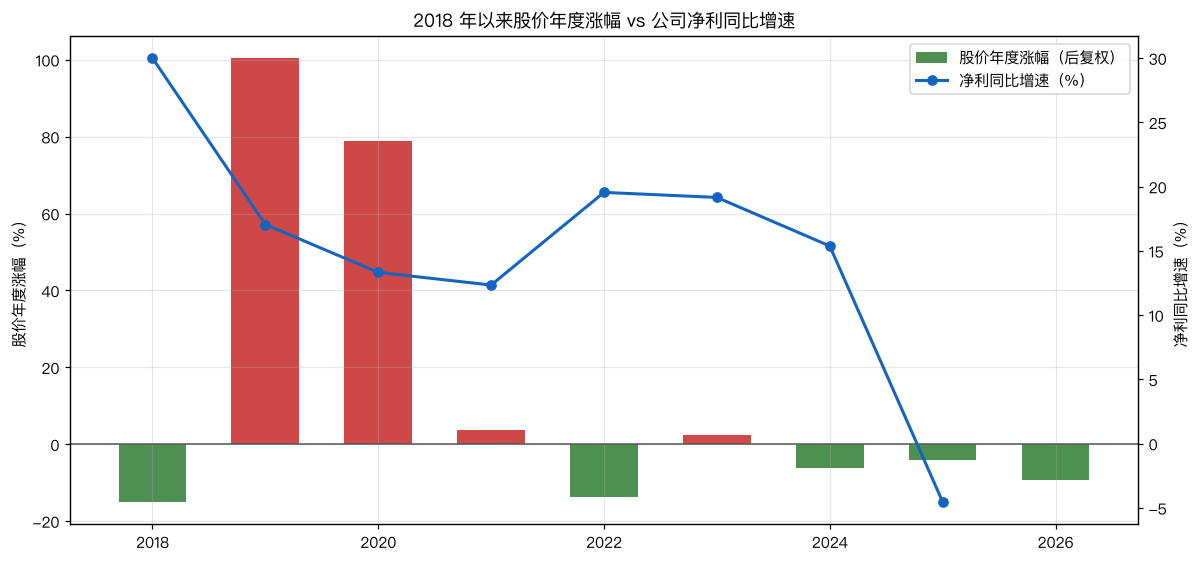

净利同比增速（%）：
 year  or_yoy  netprofit_yoy   roe  grossprofit_margin
 2018   26.49          30.00 34.46               91.14
 2019   16.01          17.05 33.12               91.30
 2020   11.10          13.33 31.41               91.41
 2021   11.88          12.34 29.90               91.54
 2022   16.87          19.55 32.41               91.87
 2023   19.01          19.16 36.18               91.96
 2024   15.71          15.38 38.43               91.93
 2025   -1.21          -4.53 34.46               91.18


In [5]:
# ------ 图3：净利增速回落 vs 股价年度表现 ------
fina = fina.drop_duplicates("end_date", keep="last").sort_values("end_date").reset_index(drop=True)
fina["year"] = fina["end_date"].astype(str).str[:4].astype(int)

recent = fina[(fina["year"] >= 2018) & (fina["year"] <= 2025)]

fig, ax1 = plt.subplots(figsize=(11, 5.2), dpi=110)
ax1.bar(annual_ret.loc[2018:].index, annual_ret.loc[2018:].values, width=0.6,
        color=["#c62828" if v >= 0 else "#2e7d32" for v in annual_ret.loc[2018:].values],
        alpha=0.85, label="股价年度涨幅（后复权）")
ax1.axhline(0, color="#555", lw=1)
ax1.set_ylabel("股价年度涨幅（%）")
ax1.set_title("2018 年以来股价年度涨幅 vs 公司净利同比增速")

ax2 = ax1.twinx()
ax2.plot(recent["year"], recent["netprofit_yoy"], marker="o", lw=2, color="#1565c0",
         label="净利同比增速（%）")
ax2.set_ylabel("净利同比增速（%）")
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right")
ax1.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print("净利同比增速（%）：")
print(recent[["year", "or_yoy", "netprofit_yoy", "roe", "grossprofit_margin"]].round(2).to_string(index=False))

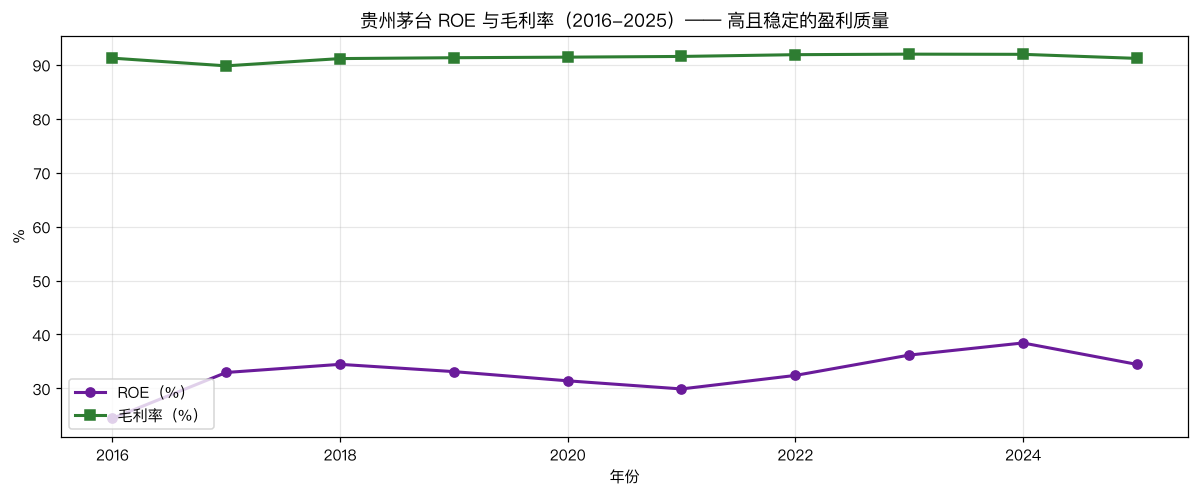

In [6]:
# ------ 图4：ROE 与毛利率的长期稳定性 ------
fig, ax = plt.subplots(figsize=(11, 4.6), dpi=110)
f_plt = fina[(fina["year"] >= 2016) & (fina["year"] <= 2025)]
ax.plot(f_plt["year"], f_plt["roe"], marker="o", lw=2, color="#6a1b9a", label="ROE（%）")
ax.plot(f_plt["year"], f_plt["grossprofit_margin"], marker="s", lw=2, color="#2e7d32",
        label="毛利率（%）")
ax.set_title("贵州茅台 ROE 与毛利率（2016-2025）—— 高且稳定的盈利质量")
ax.set_xlabel("年份"); ax.set_ylabel("%")
ax.legend(loc="lower left"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### 4.5 估值分析：市盈率 PE-TTM 的长周期视角

股价 = 业绩 × 估值。用 `daily_basic` 的 **PE-TTM** 观察市场给予茅台的估值如何在 21 年间摆荡，并计算当前估值所处的**历史分位**。

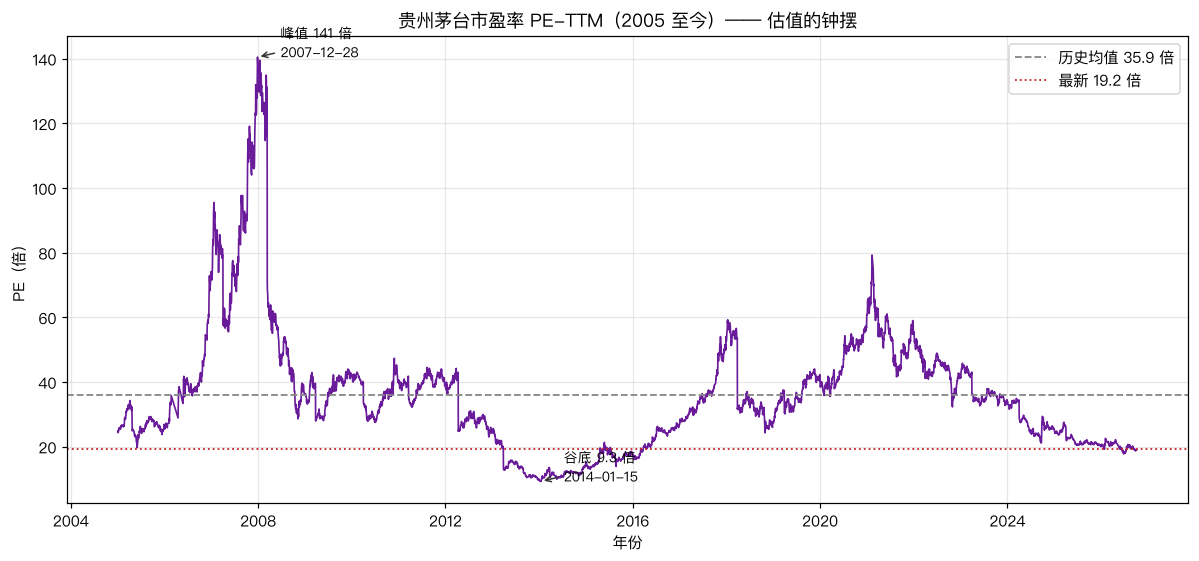

====== PE-TTM 统计（2005 至今）======
历史最高：140.5 倍（2007-12-28，2007 年大牛市顶部）
历史最低：9.3 倍（2014-01-15，白酒行业深度调整期）
2021 年初核心资产泡沫期：约 64 倍
最新值：  19.2 倍（2026-10-09）
历史均值 / 中位数：35.9 / 33.7 倍
最新值历史分位：14.1%（即比过去 14% 的交易日都便宜）


In [7]:
# ------ 图7：PE-TTM 走势（2005 至今） ------
pe = pe_df["pe"].dropna()

fig, ax = plt.subplots(figsize=(11, 5.2), dpi=110)
ax.plot(pe.index, pe, color="#6a1b9a", lw=1.1)
ax.axhline(pe.mean(), color="#888", ls="--", lw=1.2, label=f"历史均值 {pe.mean():.1f} 倍")
ax.axhline(pe.iloc[-1], color="#c62828", ls=":", lw=1.2, label=f"最新 {pe.iloc[-1]:.1f} 倍")

for d, txt in [(pe.idxmax(), f"峰值 {pe.max():.0f} 倍\n{pe.idxmax().strftime('%Y-%m-%d')}"),
               (pe.idxmin(), f"谷底 {pe.min():.1f} 倍\n{pe.idxmin().strftime('%Y-%m-%d')}")]:
    ax.annotate(txt, xy=(d, pe.loc[d]), xytext=(15, 0), textcoords="offset points",
                fontsize=9, arrowprops=dict(arrowstyle="->", color="#333"))

ax.set_title("贵州茅台市盈率 PE-TTM（2005 至今）—— 估值的钟摆")
ax.set_xlabel("年份"); ax.set_ylabel("PE（倍）")
ax.legend(loc="upper right"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

pctile = (pe < pe.iloc[-1]).mean()
print("====== PE-TTM 统计（2005 至今）======")
print(f"历史最高：{pe.max():.1f} 倍（{pe.idxmax().strftime('%Y-%m-%d')}，2007 年大牛市顶部）")
print(f"历史最低：{pe.min():.1f} 倍（{pe.idxmin().strftime('%Y-%m-%d')}，白酒行业深度调整期）")
print(f"2021 年初核心资产泡沫期：约 {pe.loc['2021-01':'2021-03'].mean():.0f} 倍")
print(f"最新值：  {pe.iloc[-1]:.1f} 倍（{pe.index[-1].strftime('%Y-%m-%d')}）")
print(f"历史均值 / 中位数：{pe.mean():.1f} / {pe.median():.1f} 倍")
print(f"最新值历史分位：{pctile:.1%}（即比过去 {pctile:.0%} 的交易日都便宜）")

### 4.6 相关性检验：股价涨幅 vs 净利增速 vs CPI

用散点图和相关系数量化检验"年度股价涨幅"与两个候选解释变量（当年净利同比增速、当年 CPI 同比均值）的线性关系。

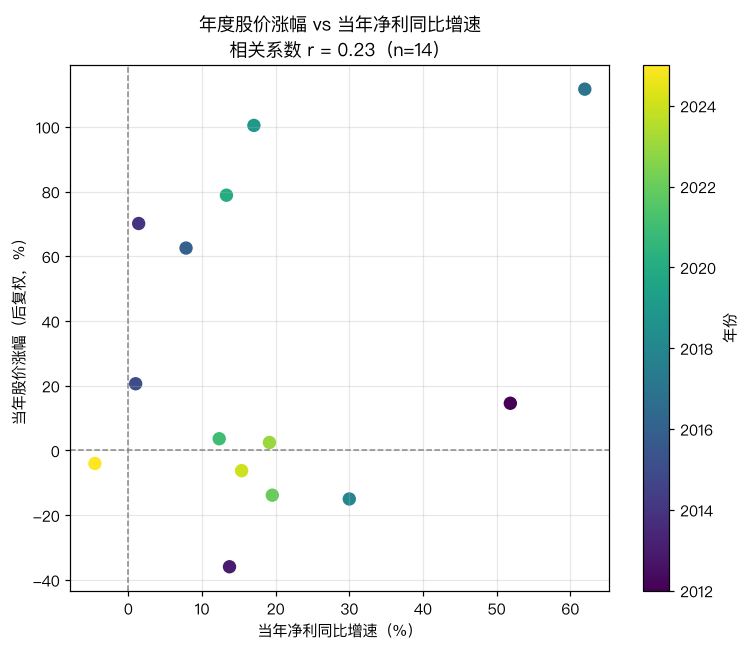


年度股价涨幅 与 当年净利增速 相关系数 r = 0.23（样本 n = 14）
年度股价涨幅 与 当年 CPI（同比均值）相关  r = 0.34（样本 n = 14）


In [8]:
# ------ 图5：年度股价涨幅 vs 当年净利增速（相关性） ------
fina_map = fina.set_index("year")["netprofit_yoy"]
pts = pd.DataFrame({"year": annual_ret.index})
pts["px_ret"] = annual_ret.values
pts["np_yoy"] = [float(fina_map.get(y, np.nan)) for y in pts["year"]]
pts = pts.dropna().sort_values("year")

corr = np.corrcoef(pts["px_ret"], pts["np_yoy"])[0, 1]

fig, ax = plt.subplots(figsize=(7, 6), dpi=110)
sc = ax.scatter(pts["np_yoy"], pts["px_ret"], c=pts["year"], cmap="viridis", s=60)
ax.axhline(0, color="#888", ls="--", lw=1); ax.axvline(0, color="#888", ls="--", lw=1)
cbar = fig.colorbar(sc); cbar.set_label("年份")
ax.set_title(f"年度股价涨幅 vs 当年净利同比增速\n相关系数 r = {corr:.2f}（n={len(pts)}）")
ax.set_xlabel("当年净利同比增速（%）"); ax.set_ylabel("当年股价涨幅（后复权，%）")
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# ----- 宏观：CPI 与股价年度表现的相关性 -----
cpi2 = cpi.copy()
cpi2["year"] = cpi2["month"].astype(str).str[:4].astype(int)
cpi_by_year = cpi2.groupby("year")["nt_yoy"].mean()
pts2 = pts.copy()
pts2["cpi"] = [float(cpi_by_year.get(y, np.nan)) for y in pts2["year"]]
pts2 = pts2.dropna()
corr_cpi = np.corrcoef(pts2["px_ret"], pts2["cpi"])[0, 1]
print(f"\n年度股价涨幅 与 当年净利增速 相关系数 r = {corr:.2f}（样本 n = {len(pts)}）")
print(f"年度股价涨幅 与 当年 CPI（同比均值）相关  r = {corr_cpi:.2f}（样本 n = {len(pts2)}）")

## 第五部分：研究结论与经验总结

### 研究结论

1. **长期超额收益极其显著**：2005-01-04 以来，贵州茅台后复权累计涨幅约 **183 倍**，同期沪深300仅约 **4.4 倍**，超额净值约 **42 倍**。若从 2001 年上市首日算起，累计涨幅超过 **300 倍**。茅台的"股王"地位有坚实的长期数据支撑。

2. **高收益的代价是高波动与深度回撤**：2005 年以来年化收益率（CAGR）约 **28%**，但年化波动率高达 **32%**；历史上最大回撤 **-62.5%**（2007-12-28 → 2008-11-07），耗时约 3.7 年（至 2011-07）才修复。25 个年度中 17 年上涨，但年涨幅中位数（14.6%）远低于均值（42.9%）——收益高度集中在少数大牛市年份（2006 +354.6%、2017 +111.6%、2019 +100.4%）。

3. **长期回报来自业绩持续高增长，而非单纯炒作**：2018—2024 年公司营收与净利连续多年双位数增长（净利增速 12%~30%），毛利率长期稳定在 **91%~92%**，ROE 长期处于 **30%~38%**。股价 25 年 300 倍的背后是净利规模的同步复合增长。

4. **业绩增速拐点叠加估值压缩，引发"戴维斯双杀"**：净利增速 2022 年 19.6% → 2023 年 19.2% → 2024 年 15.4% → **2025 年首次转负（-4.5%）**；同期 PE-TTM 从 2021 年初约 **64 倍** 一路压缩至最新 **19.2 倍**（历史 **14%** 分位），股价 2022（-13.8%）、2024（-6.2%）、2025（-4.0%）、2026 至今（-9.3%）多数年份下跌。估值钟摆的长周期规律清晰可见：**2007 年 140 倍 PE 见顶后 2008 年暴跌 50.8%；2014 年 9.3 倍 PE 见底后开启五年十倍牛市；2021 年 65 倍 PE 见顶后进入持续五年的杀估值**。

5. **短期看估值与情绪，长期看盈利**：年度股价涨幅与当年净利增速的相关系数仅约 **0.23**，与当年 CPI 的相关系数约 **0.34**（样本 14 年）——年份间的短期涨跌主要由估值、流动性与情绪主导；但拉长至十年以上尺度，股价与盈利增长的方向高度一致。**业绩决定长期中枢，估值决定买入时的安全边际，二者缺一不可。**

### 经验总结

- **tushare 使用经验**：`pro.daily`（日行情）、`pro.adj_factor`（复权因子，计算真实收益必需）、`pro.index_daily`（基准指数）、`pro.daily_basic`（估值指标）、`pro.fina_indicator`（财务指标）、`pro.cn_cpi`（宏观）覆盖了"行情—估值—基本面—宏观"完整的数据分析链路；普通 token 有接口频次限制，采用**本地缓存 + 在线抓取回退**可保证结果稳定可复现。
- **分析方法**：后复权计算真实累计收益；净值法（收盘价/起始价）比较个股与基准并直接得到超额净值；对数坐标展示大倍数增长；回撤与波动率刻画风险；历史分位定位估值；相关系数辅助判断变量间线性关系。
- **局限**：① 财务同比采用年报口径，年度收益-业绩相关性样本仅 14 年，结论以定性为主；② 估值分析只用了 PE，可结合 PB、股息率进一步验证；③ 股价与 CPI 的相关可继续扩展（如加入利率、白酒动销等变量）；④ 未与同行业（五粮液、泸州老窖）横向对比，无法区分公司个体 alpha 与行业 beta。